# Nuqta OCR quickstart

Nuqta OCR reads Arabic documents (books, scans, tables, IDs, PDFs) and turns them into text or Markdown.
It copies the tashkeel printed on the page and does not add any. The models are open: this notebook uses
[Nuqta-Arabic-OCR-0.8B](https://huggingface.co/SalahALHaismawi/Nuqta-Arabic-OCR-0.8B), which runs on a free GPU.

**Before you start, turn on a GPU:**
- Google Colab: **Runtime > Change runtime type > T4 GPU**
- Kaggle: **Settings > Accelerator > GPU T4 x2**, and turn **Internet** on

Then run the cells from top to bottom. Library and docs: [github.com/SalahAlHaismawi/nuqta-ocr](https://github.com/SalahAlHaismawi/nuqta-ocr)

In [ ]:
# Nuqta needs transformers 5.2 or newer (Colab already has it; older images get upgraded)
%pip install -q nuqta-ocr "transformers>=5.2"

## Load the model

The 0.8B model is a 1.7 GB download. The T4 has no bfloat16 support, so the model runs in float16 there
(we checked: float16 gives the same text as bfloat16). Warnings about `causal_conv1d` or
`flash-linear-attention` only mean the built-in, slower code path is used; the text is the same.

In [1]:
import torch
from nuqta import OCR

assert torch.cuda.is_available(), "No GPU found: turn one on (see the first cell) and run again."
dtype = "bfloat16" if torch.cuda.get_device_capability()[0] >= 8 else "float16"  # T4 -> float16
print(torch.cuda.get_device_name(0), "->", dtype)

ocr = OCR("nuqta-0.8b", backend="transformers", dtype=dtype, device_map="cuda")

NVIDIA GeForce RTX 5090 Laptop GPU -> bfloat16


## Read a page

A page from a children's story with full tashkeel. The default mode, `as-written`, keeps the tashkeel exactly
where it is printed.

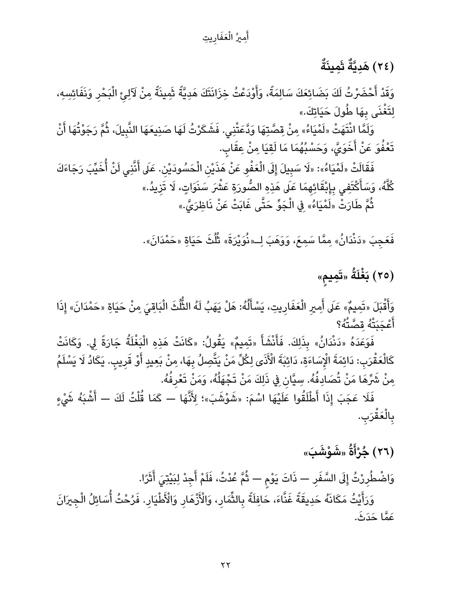

أَمِيرُ الْعَفَارِيتِ (٢٤) هَدِيَّةٌ ثَمِينَةٌ وَقَدْ أَحْضَرْتُ لَكَ بَضَائِعَكَ سَالِمَةً، وَأَوْدَعْتُ خِزَانَتَكَ هَدِيَّةً ثَمِينَةً مِنْ لآلِئِ الْبَحْرِ وَنَفَائِسِهِ، لِتَغْنَى بِهَا طُولَ حَيَاتِكَ.» وَلَمَّا انْتَهَتْ «لَمْيَاءُ» مِنْ قِصَّتِهَا وَدَّعَتْنِي. فَشَكَرْتُ لَهَا صَنِيعَهَا النَّبِيلَ، ثُمَّ رَجَوْتُهَا أَنْ تَعْفُوَ عَنْ أَخَوَيَّ، وَحَسْبُهُمَا مَا لَقِيَا مِنْ عِقَابٍ. فَقَالَتْ «لَمْيَاءُ»: «لَا سَبِيلَ إِلَى الْعَفْوِ عَنْ هَذَيْنِ الْحَسُودَيْنِ. عَلَى أَنَّنِي لَنْ أُخَيِّبَ رَجَاءَكَ كُلَّهُ، وَسَأَكْتَفِي بِإِبْقَائِهِمَا عَلَى هَذِهِ الصُّورَةِ عَشْرَ سَنَوَاتٍ، لَا تَزِيدُ.» ثُمَّ طَارَتْ «لَمْيَاءُ» فِي الْجَوِّ حَتَّى غَابَتْ عَنْ نَاظِرَيَّ.» فَعَجِبَ «دَنْدَانُ» مِمَّا سَمِعَ، وَوَهَبَ لِ«نُوَيْرَةَ» ثُلُثَ حَيَاةِ «حَمْدَانَ». (٢٥) بَغْلَةُ «تَمِيمٍ» وَأَقْبَلَ «تَمِيمٌ» عَلَى أَمِيرِ الْعَفَارِيتِ، يَسْأَلُهُ: هَلْ يَهَبُ لَهُ الثُّلُثَ الْبَاقِيَ مِنْ حَيَاةِ «حَمْدَانَ» إِذَا أَعْجَبَتْهُ قِصَّتُهُ؟ فَوَعَدَهُ «دَنْدَانُ» بِذَلِكَ. فَأَنْشَأَ «

In [2]:
import urllib.request
from PIL import Image

def fetch(name):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/SalahAlHaismawi/nuqta-ocr/main/space/assets/" + name, name)
    return name

page = fetch("9_tashkeel_story.png")
display(Image.open(page).resize((450, 600)))

result = ocr.read(page)
print(result.text)

## Tables and layout: Markdown mode

`mode="markdown"` keeps headings and paragraphs and writes tables as HTML. Other modes: `bare` (text without
tashkeel) and `id` (passports and ID cards, with MRZ check digits in `result.fields`).

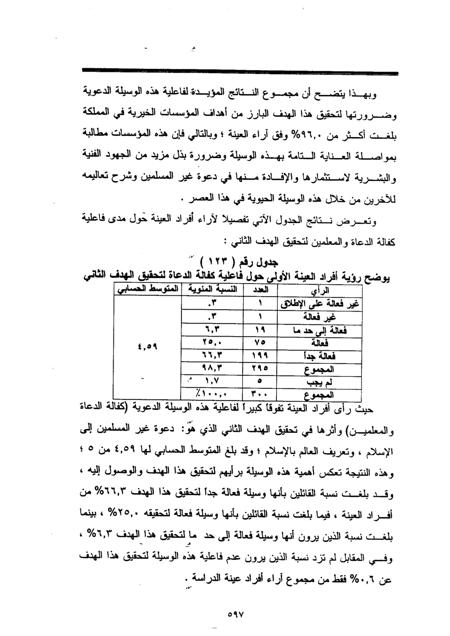

وبهذا يتضح أن مجموع النتائج المؤيدة لفاعلية هذه الوسيلة الدعوية
وضرورتها لتحقيق هذا الهدف البارز من أهداف المؤسسات الخيرية في المملكة
بلغت أكثر من ٩٦,٠% وفق آراء العينة؛ وبالتالي فإن هذه المؤسسات مطالبة
بمواصلة العناية التامة بهذه الوسيلة وضرورة بذل مزيد من الجهود الفنية
والبشرية لاستثمارها والإفادة منها في دعوة غير المسلمين وشرح تعاليمه
للآخرين من خلال هذه الوسيلة الحيوية في هذا العصر.
وتعرض نتائج الجدول الآتي تفصيلا لآراء أفراد العينة حول مدى فاعلية
كفالة الدعاة والمعلمين لتحقيق الهدف الثاني:
جدول رقم ( ١٢٣ )
يوضح رؤية أفراد العينة الأولى حول فاعلية كفالة الدعاة لتحقيق الهدف الثاني
<table>
<thead>
<tr><th>الرأي</th><th>العدد</th><th>النسبة المئوية</th><th>المتوسط الحسابي</th></tr>
</thead>
<tbody>
<tr><td>غير فعالة على الإطلاق</td><td>١</td><td>٣</td><td rowspan="11">٤,٥٩</td></tr>
<tr><td>غير فعالة</td><td>١</td><td>٣</td></tr>
<tr><td>فعالة إلى حد ما</td><td>١٩</td><td>٦,٣</td></tr>
<tr><td>فعالة</td><td>٧٥</td><td>٢٥,٠</td></tr>
<tr><td>فعالة جداً</td><td>١٩٩</td><td>٦٦,٣</td></tr

In [3]:
table_page = fetch("2_table.png")
display(Image.open(table_page).resize((450, 636)))

result = ocr.read(table_page, mode="markdown")
print(result.text)

## Your own image or PDF

On Colab this cell opens a file picker. PDFs are read page by page. On Kaggle or your own machine,
put the file paths in `paths` instead. Each result is also saved next to the file as `.md`.

In [ ]:
from pathlib import Path

paths = []  # e.g. ["/kaggle/input/my-scans/page1.jpg", "report.pdf"]
try:
    from google.colab import files
    paths = list(files.upload())
except ImportError:
    pass  # not on Colab

for p in paths:
    result = ocr.read(p, mode="markdown")  # or mode="as-written", "bare", "id"
    Path(p).with_suffix(".md").write_text(result.text, encoding="utf-8")
    print(f"--- {p} ({len(result.pages)} page(s))")
    print(result.text)

## Optional: the 4B model

The 4B is more accurate (first on KITAB-Bench and Misraj-DocOCR) and slower. It is a 9 GB download and
fits on a T4 in float16. This cell frees the 0.8B first.

In [ ]:
import gc

del ocr
gc.collect()
torch.cuda.empty_cache()

ocr = OCR("nuqta-4b", backend="transformers", dtype=dtype, device_map="cuda")
print(ocr.read(page).text)

For faster batched reading on your own GPU, install `nuqta-ocr[vllm]`. The README lists the command line,
the GGUF builds for llama.cpp and the phone apps.